In [79]:
%matplotlib inline
from scipy.integrate import solve_ivp
from scipy.interpolate import BarycentricInterpolator
from Gaussian_Quadrature import gauss_radau_left
import numpy as np
import scipy as sp
from scipy import linalg
from scipy import interpolate
from scipy import integrate
from scipy import special
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import itertools as itertools
from scipy.optimize import minimize
import time
from IPython.display import clear_output

# Gauss-Hermite collocation method

T. Tang, ``The Hermite Spectral Method for Gaussian-Type Functions'', SIAM J. Sci. Comput., Vol. 14, No. 3, 1993

The orthogonal basis functions are
\begin{equation}
    \psi_n(x) = \frac{1}{\sqrt{2^n n !}} H_n(x) e^{-x^2/2},
\end{equation}
where $H_n$ are the physicist's Hermite Polynomials and we have
\begin{equation}
    \left\langle \psi_i, \ \psi_j \right\rangle = \int_{-\infty}^{\infty} \psi_i(x) \psi_j(x) \text{d}x = \frac{1}{2^n n!} \int_{-\infty}^{\infty} H_i(x) H_j(x) e^{-x^2} \text{d}x = \sqrt{\pi} \delta_{i,j}.
\end{equation}

In [50]:
# evaluate basis functions
def psi_fun(n, x):
    if n < 201: # direct calculation
        Hn = sp.special.eval_hermite(n, x)
        z = np.square(x) + n*np.log(2) + sp.special.gammaln(n+1)
        psi = Hn * np.exp(-z/2.0)
    else: # recursive calculation
        psi0 = np.sqrt(2/n)*x*psi_fun(n-1, x) 
        psi1 = np.sqrt((n-1)/n)*psi_fun(n-2, x)
        psi = psi0 - psi1
    return psi

## Gauss-Hermite interpolation and differentiation matrices

J. A. C. Weideman and S. C. Reddy, ``A MATLAB Differentiation Matrix Suite'', ACM Trans. Math. Softw., 2000

In [51]:
def herdif(N, order):
    D_mats = [_ for _ in range(order)]
    
    # define collocation points
    x_coll, _ = sp.special.roots_hermite(N)
    
    # define constants c using equation (5 in W&R)
    c = np.exp(-np.square(x_coll)/2.0)
    for j in range(N):
        for k in range(j):
            c[j] = c[j]*(x_coll[j] - x_coll[k])
        
        for k in range(j+1,N):
            c[j] = c[j]*(x_coll[j] - x_coll[k])
    
    C = np.zeros((N,N))
    for i in range(N):
        for j in range(N):
            C[i,j] = c[i] / c[j]
    
    # compute beta's using equation (18 in W&R)
    B = np.zeros((order, N))
    bn1 = np.zeros(N)
    b0 = np.ones(N)
    for l in range(order):
        B[l,:] = -x_coll*b0 - l*bn1
        bn1 = np.copy(b0)
        b0 = np.copy(B[l,:])
    
    # define matrix Z
    Z = np.zeros((N,N))
    for i in range(N):
        for j in range(i+1, N):
            Z[i,j] = 1.0/(x_coll[i] - x_coll[j])
            Z[j,i] = 1.0/(x_coll[j] - x_coll[i])
    
    # define matrix X
    X = np.zeros((N-1,N))
    for i in range(N-1):
        for j in range(i+1):
            X[i,j] = 1.0/(x_coll[j] - x_coll[i+1])
        
        for j in range(i+1, N):
            X[i,j] = 1.0/(x_coll[j] - x_coll[i])
    
    # main recursion described in Table II of W&R
    Y = np.ones((N-1,N))
    D = np.eye(N)
    for l in range(order):
        # recursion for diagonals
        Y = np.cumsum( np.vstack([ np.reshape(B[l,:], (1,-1)) ,\
                                   (l+1)* Y[:N-1,:]*X ]), axis=0 )
        
        # recursion for off-diagonals
        D_rep = np.reshape(np.diag(D), (-1,1)) * np.ones((N,N))
        D = (l+1) * Z * (C * D_rep - D)
        
        # correct the diagonal of D
        for i in range(N):
            D[i,i] = Y[N-1, i]
        
        D_mats[l] = D
    
    return x_coll, D_mats

def herterp(N, x):
    # construct interpolation matrix mapping
    # f at collocation points to its interpolated values at x
    # (works up to about N=200)
    
    # collocation points
    x_coll, _ = sp.special.roots_hermite(N)
    
    # evaluation of hermite polynomials
    HN_x = sp.special.eval_hermite(N, x)
    dHN_coll = - sp.special.eval_hermite(N+1, x_coll)
    
    # Interpolation matrix
    R = np.zeros((len(x), N))
    for i in range(len(x)):
        for j in range(N):
            if np.absolute(x[i] - x_coll[j]) > 1.0e-12:
                phi = HN_x[i] / (dHN_coll[j] * (x[i] - x_coll[j]))
                R[i,j] = phi * np.exp(-np.square(x[i])/2 + np.square(x_coll[j])/2)
            else:
                R[i,j] = 1.0
    
    return R

## Test differentiation matrices

Text(0.5, 0, 'x')

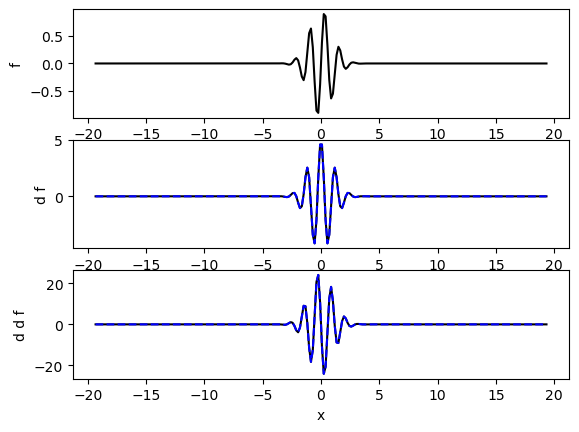

In [52]:
# a function and its derivatives
w = 5
f_test = lambda x: np.sin(w*x)*np.exp(-np.square(x)/2.0)
df_test = lambda x: w*np.cos(w*x)*np.exp(-np.square(x)/2.0) - np.sin(w*x)*x*np.exp(-np.square(x)/2.0)
d2f_test = lambda x: -np.square(w)*np.sin(w*x)*np.exp(-np.square(x)/2.0) - w*np.cos(w*x)*x*np.exp(-np.square(x)/2.0) \
                        - w*np.cos(w*x)*x*np.exp(-np.square(x)/2.0) - np.sin(w*x)*np.exp(-np.square(x)/2.0) \
                        + np.sin(w*x)*np.square(x)*np.exp(-np.square(x)/2.0)

# number of collocation points
N = 200

# collocation points and differentiation matrices
xi_coll, D_mats = herdif(N, 2)


# evaluate function at collocation points
f_coll = f_test(xi_coll)

# approximation of first derivative
df_coll = np.dot(D_mats[0], f_coll)

# approximation of second derivative
ddf_coll = np.dot(D_mats[1], f_coll)


fig = plt.figure()

ax = fig.add_subplot(3,1,1)
ax.plot(xi_coll, f_coll, color='k', linestyle='-', label='f')
ax.set_ylabel('f')

ax = fig.add_subplot(3,1,2)
ax.plot(xi_coll, df_test(xi_coll), color='k', linestyle='-', label='df')
ax.plot(xi_coll, df_coll, color='b', linestyle='--', label='df approx.')
ax.set_ylabel('d f')

ax = fig.add_subplot(3,1,3)
ax.plot(xi_coll, d2f_test(xi_coll), color='k', linestyle='-', label='df')
ax.plot(xi_coll, ddf_coll, color='b', linestyle='--', label='df approx.')
ax.set_ylabel('d d f')
ax.set_xlabel('x')

## Test interpolation matrices

Text(0.5, 0, 'x')

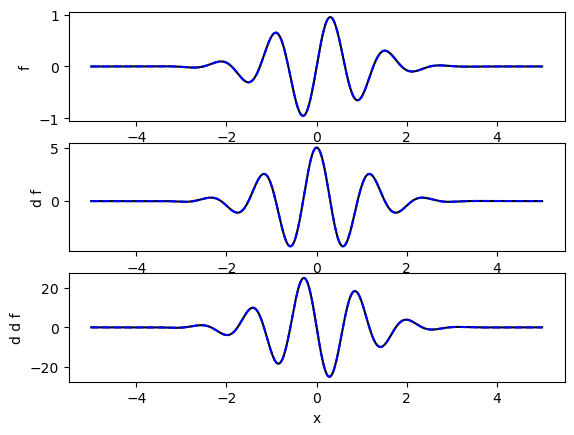

In [53]:
# interpolation points
xi_terp = np.linspace(-5, 5, 501)

# interpolation matrix
R_coll2terp = herterp(N, xi_terp)

# interpolate the function and its derivatives
f_terp = np.dot(R_coll2terp, f_coll)

df_terp = np.dot(R_coll2terp, df_coll)

ddf_terp = np.dot(R_coll2terp, ddf_coll)


fig = plt.figure()

ax = fig.add_subplot(3,1,1)
ax.plot(xi_terp, f_test(xi_terp), color='k', linestyle='-', label='f')
ax.plot(xi_terp, f_terp, color='b', linestyle='--', label='f approx.')
ax.set_ylabel('f')

ax = fig.add_subplot(3,1,2)
ax.plot(xi_terp, df_test(xi_terp), color='k', linestyle='-', label='df')
ax.plot(xi_terp, df_terp, color='b', linestyle='--', label='df approx.')
ax.set_ylabel('d f')

ax = fig.add_subplot(3,1,3)
ax.plot(xi_terp, d2f_test(xi_terp), color='k', linestyle='-', label='df')
ax.plot(xi_terp, ddf_terp, color='b', linestyle='--', label='df approx.')
ax.set_ylabel('d d f')
ax.set_xlabel('x')

# Complex Ginzburg-Landau Equation

\begin{equation}
    \frac{\partial q}{\partial t} = \left(- \nu \frac{\partial}{\partial x} + \gamma \frac{\partial^2}{\partial x^2} + \mu\right) q - a \vert q\vert^2 q + b u
\end{equation}

\begin{equation}
    \nu = U + 2 i c_u, \qquad \gamma = 1 + i c_d, \qquad \mu(x) = (\mu_0 - c_u^2) + \frac{1}{2} \mu_2 x^2
\end{equation}

See S. Bagheri, D. S. Henningson, J. Hoepffner, and P. J. Schmid, ''Input-Output Analysis and Control Design Applied to a Linear Model of Spatially Developing Flows'', Applied Mechanics Reviews, 2009.

Letting $\chi$ be a scaling factor so that $\chi x = \xi$, these equations become
\begin{equation}
    \frac{\partial q}{\partial t} = \left(- \nu \chi \frac{\partial}{\partial \xi} + \gamma \chi^2 \frac{\partial^2}{\partial \xi^2} + \mu\right) q - a \vert q\vert^2 q.
\end{equation}

We use the same scaling parameter value $\chi = \vert \mu_2 / (2\gamma)\vert^{1/4}$ as in S. Bagheri et al..
While the term stated in S. Bagheri has a typo, this parameter can be found in J.-M. Chomaz, ''Global Instabilities in Spatially Developing Flows: Non-Normality and Nonlinearity'', Annual Review of Fluid Mechanics, 2005.

The nonlinearity in the CGL equation is not analytic, making it impossible to compute complex Jacobians and gradients about any point besides the origin.
Therefore, we work with real variables $q = q_r + i q_i$, yielding the real system
\begin{equation}
\begin{aligned}
    \frac{\partial q_r}{\partial t} &= \left( -U \chi \frac{\partial}{\partial \xi} + \chi^2 \frac{\partial^2}{\partial \xi^2} + \mu \right) q_r + \left( 2 c_u \chi \frac{\partial}{\partial \xi} - c_d \chi^2 \frac{\partial^2}{\partial \xi^2} \right) q_i - a \left( q_r^2 + q_i^2 \right) q_r + b_r u_r - b_i u_i \\
    \frac{\partial q_i}{\partial t} &= \left( -2 c_u \chi \frac{\partial}{\partial \xi} + c_d \chi^2 \frac{\partial^2}{\partial \xi^2} \right) q_r + \left( -U \chi \frac{\partial}{\partial \xi} + \chi^2 \frac{\partial^2}{\partial \xi^2} + \mu \right) q_i - a \left( q_r^2 + q_i^2 \right) q_i + b_i u_r + b_r u_i.
\end{aligned}
\end{equation}

We use the complex-valued linear observation defined by
\begin{equation}
    y(q) = \int_{-\infty}^{\infty} \exp{\left[-\left(\frac{x - x_2}{s}\right)^2\right]} q(x) \text{d}x, \qquad s=1.6, \quad x_2 = \sqrt{-2(\mu_0 - c_u^2)/\mu_2}.
\end{equation}
This observation was used in M. Ilak, S. Bagheri, L. Brandt, C. W. Rowley, and D. S. Henningson, ''Model Reduction of the Nonlinear Complex Ginzburg-Landau Equation'', SIAM J. Applied Dynamical Systems, 2010.

Similarly, we have a complex-valued input $u(t)$ and
\begin{equation}
    b(x) = \exp{\left[-\left(\frac{x - x_1}{s}\right)^2\right]}, \qquad s=1.6, \quad x_1 = -\sqrt{-2(\mu_0 - c_u^2)/\mu_2}.
\end{equation}

In [54]:
## CGL parameters

# nonnormal case
U = 2.0
# normal case
# U = 0.0


cu = 0.2 
nu = U + 2j*cu

# Illak nonnormal case
cd = -1 
# normal case
# cd = 0.0

gam = 1.0 + 1j*cd

# Illak subcritical case:
#mu0 =  0.38
# Illak supercritical case:
mu0 =  0.41 #The default is 0.41 

# subcritical normal case
# mu0 = 0.053
# supercritical normal case
# mu0 = 0.083

mu2 = -0.01

mu_fun = lambda x: (mu0 - np.square(cu)) + mu2*np.square(x)/2.0 

a = 0.1
#This is the initial value
#a= 0.1  

chi = np.power(np.absolute(mu2 / (2.0*gam)), 1.0/4.0)

# width of the observation kernel
s_obs = 1.6

# width of the input kernel
s_inpt = 1.6

# branches (upstream and downstream bounds of unstable region)
branch_1 = - np.sqrt(-2.0*(mu0-np.square(cu))/mu2)
branch_2 = np.sqrt(-2.0*(mu0-np.square(cu))/mu2)

## Collocation method

# number of collocation points
nx = 220

# number of Gauss-Hermite functions to use for initial conditions
nGH_IC = 100

# collocation points and differentiation operators
xi_coll, Dxi_mats = herdif(nx, 2)

# quadrature weights
_, w = sp.special.roots_hermite(nx)
w_quad = w*np.exp(np.square(xi_coll)) / chi

# # test quadrature by integrating a normalized Gaussian distribution
# f_test = lambda x: np.exp(-np.square(x)/2.0) / np.sqrt(2.0*np.pi)
# print(np.sum(w_quad*f_test(xi_coll/chi)))
# print(np.dot(psi_fun(2, xi_coll), chi*w_quad*psi_fun(2, xi_coll)) / np.sqrt(np.pi))

## Assemble the discretized CGL operators
The discretized CGL equation is written as a dynamical system
\begin{equation}
\begin{aligned}
    \dot{\mathbf{q}} &= \mathbf{A} \mathbf{q} + \mathbf{f}_{N}(\mathbf{q}) + \mathbf{B}\mathbf{u} \\
    \mathbf{y} &= \mathbf{C} \mathbf{q}
\end{aligned}
\end{equation}
with state vector is
\begin{equation}
    \mathbf{q} = \left( \sqrt{w_1} q_r(\xi_1),\ \ldots,\ \sqrt{w_N} q_r(\xi_N),\ \sqrt{w_1} q_i(\xi_1),\ \ldots,\ \sqrt{w_N} q_i(\xi_N) \right)
\end{equation}
having the Euclidean norm
\begin{equation}
   \Vert \mathbf{q} \Vert^2 = \mathbf{q}^T \mathbf{q} = \sum_{i=1}^N w_i \left( q_r(\xi_i)^2 + q_i(\xi_i)^2 \right) \approx \int_{-\infty}^{\infty} \vert q(x) \vert^2 \text{d}x
\end{equation}
where $w_i$ are Gauss-Hermite quadrature weights.

In [55]:
n_states = 2*nx
n_inputs = 2
n_outputs = 2
n_IC = 2*nGH_IC #2 times number of gauss hermite functions used for initial condition 

# evaluate mu at collocation points
mu_coll = mu_fun(xi_coll/chi)

# Linear operators for CGL in state space with weighted inner product
Lrr = -U*chi*Dxi_mats[0] + np.square(chi)*Dxi_mats[1] + np.diag(mu_coll)
Lri = 2*cu*chi*Dxi_mats[0] - cd*np.square(chi)*Dxi_mats[1]
Lir = -2*cu*chi*Dxi_mats[0] + cd*np.square(chi)*Dxi_mats[1]
Lii = -U*chi*Dxi_mats[0] + np.square(chi)*Dxi_mats[1] + np.diag(mu_coll)

# Linear operators for CGL in Euclidean state space
Arr = np.reshape(np.sqrt(w_quad),(-1,1)) * Lrr / np.reshape(np.sqrt(w_quad),(1,-1))
Ari = np.reshape(np.sqrt(w_quad),(-1,1)) * Lri / np.reshape(np.sqrt(w_quad),(1,-1))
Air = np.reshape(np.sqrt(w_quad),(-1,1)) * Lir / np.reshape(np.sqrt(w_quad),(1,-1))
Aii = np.reshape(np.sqrt(w_quad),(-1,1)) * Lii / np.reshape(np.sqrt(w_quad),(1,-1))

# linear operator for the discretized CGL equation in Euclidean state space
A_FOM = np.vstack([ np.hstack([Arr, Ari]), np.hstack([Air, Aii]) ])

## Observation

# observation kernel defined by eqn. 4.1 in M. Ilak et al.
ker_obs = np.exp(-np.square((xi_coll/chi - branch_2)/s_obs))

# define similar kernel for input, but centered at branch 1
ker_inpt = np.exp(-np.square((xi_coll/chi - branch_1)/s_inpt))

# define observations on the Euclidean state space
C_FOM = np.zeros((2, 2*nx))
C_FOM[0,:nx] = ker_obs * np.sqrt(w_quad)
C_FOM[1,nx:] = ker_obs * np.sqrt(w_quad)

# define inputs
B_FOM = np.zeros((2*nx, 2))
B_FOM[:nx,0] = ker_inpt * np.sqrt(w_quad)
B_FOM[nx:,1] = ker_inpt * np.sqrt(w_quad)


## Basis for initial conditions
# use leading nGH_inputs Gauss-Hermite functions for ICs on real and imaginary components
# meaning there are 2*nGH_IC components.
Psi_vals = np.array([np.sqrt(chi/np.sqrt(np.pi))*psi_fun(n, xi_coll) for n in range(nGH_IC)]).T
B_IC = np.zeros((n_states, 2*nGH_IC))
B_IC[:nx,:nGH_IC] = Psi_vals
B_IC[nx:, nGH_IC:] = Psi_vals

print(f"The shape of A_FOM is {A_FOM.shape}")
print(f"The shape of B_FOM is {B_FOM.shape}")
print(f"The shape of C_FOM is {C_FOM.shape}")
print(f"The shape of initial conditions is {B_IC.shape}")
print(f"The shape of B_IC is {B_IC.shape}")

The shape of A_FOM is (440, 440)
The shape of B_FOM is (440, 2)
The shape of C_FOM is (2, 440)
The shape of initial conditions is (440, 200)
The shape of B_IC is (440, 200)


In [56]:
# operators in complex variables
L_CGL = -nu*chi*Dxi_mats[0] + gam*np.square(chi)*Dxi_mats[1] + np.diag(mu_coll)

# convert to Euclidean state space
A_CGL = np.reshape(np.sqrt(w_quad),(-1,1)) * L_CGL / np.reshape(np.sqrt(w_quad),(1,-1))

## Eigen-decomposition of linearized operator

In [57]:
# eigendecomposition of linearized dynamics at the origin
lam, Vl, Vr = sp.linalg.eig(A_FOM, left=True, right=True)

# biorthogonalize left and right eigenvectors
w = np.diag(np.dot(np.conj(Vr).T, Vl))
Vl = Vl/w

# sort the eigenvalues in order of decreasing real part
idcs = np.argsort(np.real(lam))[::-1]
lam_A_FOM = lam[idcs]
Vl_A_FOM = Vl[:,idcs]
Vr_A_FOM = Vr[:,idcs]

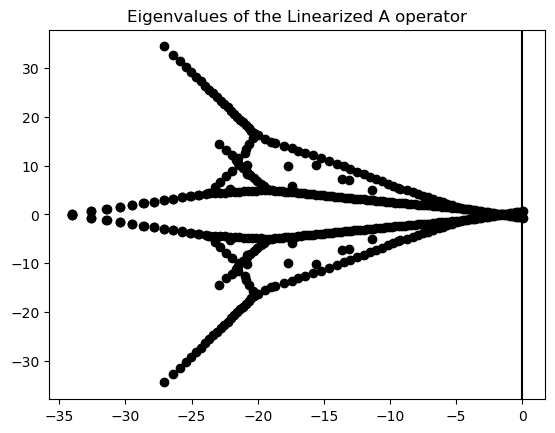

In [58]:
plt.figure()
plt.plot(np.real(lam_A_FOM), np.imag(lam_A_FOM), 'ko')
plt.title(f'Eigenvalues of the Linearized A operator')
plt.axvline(x=0.0, color='k')
plt.show()

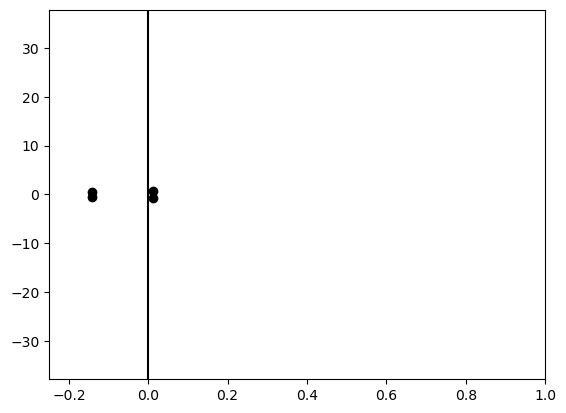

In [59]:
plt.figure()
plt.plot(np.real(lam_A_FOM), np.imag(lam_A_FOM), 'ko')
plt.axvline(x=0.0, color='k')
plt.xlim([-0.25,1])
plt.show()

In [60]:
# leading eigenvectors are complex conjugate pairs, rotate to real pairs
Q = np.array([[1, -1j], [1, 1j]]) / np.sqrt(2)

# define the input matrix using the leading right eigenvectors
# these are tangent to the slowest 2D SSM, which in the supercritical case is the unstable manifold
B_mfd = np.real(np.dot(Vr_A_FOM[:,:2], Q))

## Define FOM dynamical system, linearization, and adjoint
Everything is in Euclidean state space, where qE is the Euclidean state variable

In [61]:
# full-order model
def FOM(qE, u):
    # real and imaginary parts in original state space
    qr = qE[:nx]/np.sqrt(w_quad)
    qi = qE[nx:]/np.sqrt(w_quad)
    
    # evaluate nonlinearity
    fN = np.zeros(n_states)
    fN[:nx] = np.sqrt(w_quad)*(np.square(qr) + np.square(qi))*qr
    fN[nx:] = np.sqrt(w_quad)*(np.square(qr) + np.square(qi))*qi
    
    # dynamics
    #f = np.dot(A_FOM, qE) - a*fN 
    f = np.dot(A_FOM, qE) - a*fN + np.dot(B_FOM, u)
    return f

# Nonlinearity of the FOM 
def cubic_FOM(qE):
    qr = qE[:nx] / np.sqrt(w_quad)
    qi = qE[nx:] / np.sqrt(w_quad)

    fN = np.zeros_like(qE)
    fN[:nx] = np.sqrt(w_quad) * (qr**2 + qi**2) * qr
    fN[nx:] = np.sqrt(w_quad) * (qr**2 + qi**2) * qi
    return fN

# full-order model
def FOM_limit_cycle(qE, u):
    # real and imaginary parts in original state space
    qr = qE[:nx]/np.sqrt(w_quad)
    qi = qE[nx:]/np.sqrt(w_quad)
    
    # evaluate nonlinearity
    fN = np.zeros(n_states)
    fN[:nx] = np.sqrt(w_quad)*(np.square(qr) + np.square(qi))*qr
    fN[nx:] = np.sqrt(w_quad)*(np.square(qr) + np.square(qi))*qi
    
    # dynamics
    f = np.dot(A_FOM, qE) -  a*fN 
    return f

# derivative of full-order model acting on v
def d_FOM(qE, u, vE):
    # real and imaginary parts of v in Euclidean state space
    vEr = vE[:nx]
    vEi = vE[nx:]
    
    # real and imaginary parts of state in original state space
    qr = qE[:nx]/np.sqrt(w_quad)
    qi = qE[nx:]/np.sqrt(w_quad)
    
    # derivative of the nonlinearity
    dfN_vE = np.zeros(n_states)
    dfN_vE[:nx] = (3*np.square(qr) + np.square(qi))*vEr + 2*qr*qi*vEi
    dfN_vE[nx:] = 2*qi*qr*vEr + (3*np.square(qi) + np.square(qr))*vEi
    
    df_vE = np.dot(A_FOM, vE) - a*dfN_vE
    return df_vE

# Jacobian matrix for the full-order model
def Jac_FOM(qE, u):
    # real and imaginary parts in original state space
    qr = qE[:nx]/np.sqrt(w_quad)
    qi = qE[nx:]/np.sqrt(w_quad)
    
    # Jacobian for the nonlinearity
    JNrr = np.diag(3*np.square(qr) + np.square(qi))
    JNri = np.diag(2*qr*qi)
    JNir = np.diag(2*qi*qr)
    JNii = np.diag(3*np.square(qi) + np.square(qr))
    JN = np.vstack([ np.hstack([JNrr, JNri]), np.hstack([JNir, JNii]) ])
    
    return A_FOM - a*JN

# adjoint of FOM acting on w
def d_FOM_adj(qE, u, wE):
    # real and imaginary parts of w in Euclidean state space
    wEr = wE[:nx]
    wEi = wE[nx:]
    
    # real and imaginary parts of state in original state space
    qr = qE[:nx]/np.sqrt(w_quad)
    qi = qE[nx:]/np.sqrt(w_quad)
    
    # transposed derivative of the nonlinearity
    dfN_T_vE = np.zeros(n_states)
    dfN_T_vE[:nx] = (3*np.square(qr) + np.square(qi))*wEr + 2*qi*qr*wEi
    dfN_T_vE[nx:] = 2*qr*qi*wEr + (3*np.square(qi) + np.square(qr))*wEi
    
    #df_T_wE = np.dot(A_FOM.T, wE) - a*dfN_T_vE
    df_T_wE = np.dot(A_FOM.T, wE) - a*dfN_T_vE   #Correct formulation for my Case
    return df_T_wE

# observation function
def FOM_obs(qE):
    return C_FOM @ qE

# derivative of observation function acting on v
def d_FOM_obs(qE, vE):
    return np.dot(C_FOM, vE)

# transpose of derivative of observation function acting on w
def d_FOM_obs_adj(qE, wE):
    return np.dot(C_FOM.T, wE)

## Validate FOM derivative
eps = 1.0e-8
q = np.random.randn(n_states)
v = np.random.randn(n_states)
u = np.random.randn(n_inputs)
df_v_fd = (FOM(q + eps*v, u) - FOM(q, u)) / eps
df_v = d_FOM(q, u, v)
df_v_Jac = np.dot(Jac_FOM(q, u), v)
print(np.linalg.norm(df_v - df_v_fd) / np.linalg.norm(df_v_fd)) # should be very small
print(np.linalg.norm(df_v_Jac - df_v_fd) / np.linalg.norm(df_v_fd)) # should be very small

## Validate FOM adjoint
w = np.random.randn(n_states)
IP1 = np.dot(w, df_v)
df_T_w = d_FOM_adj(q, u, w)
IP2 = np.dot(df_T_w, v)
print(IP1, IP2)
print(np.absolute(IP2 - IP1) / np.absolute(IP1)) # should be very small

3.651788927761942e-08
3.651788927888546e-08
190.45608828182617 190.4560882818257
2.3876755791264318e-15


# Generate randomly-forced data

In [62]:
n_freqs = 101
forcing_freqs = 2*np.pi*np.linspace(0, 25, n_freqs)/100
forcing_pwr = 0.1
forcing_amps = forcing_pwr * np.random.randn(n_inputs, n_freqs) / np.sqrt(n_inputs*n_freqs)
def u_fun(t):
    if len(np.shape(t)) == 0:
        u = np.dot(forcing_amps, np.sqrt(2)*np.sin(forcing_freqs * t))
    elif len(np.shape(t)) == 1:
        u = np.dot(forcing_amps, np.sqrt(2)*np.sin(np.outer(forcing_freqs, t)))
    return u

In [63]:
np.random.seed(42) 
n_traj = 50

# The value of 0.15 is to scale the radius of initial conditions to that of the limit cycle which is ~ 2.5
traj_ICs = [0.15 * (B_IC @ np.random.randn(2*nGH_IC)) for _ in range(n_traj)]

t_data = np.linspace(0, 100, 1001)

idx = 0   # Choose which IC to simulate: 0, 1, ..., 49
y0 = traj_ICs[idx]

sol = sp.integrate.solve_ivp(lambda t, q: FOM_limit_cycle(q, u_fun(t)), [t_data[0], t_data[-1]], y0, t_eval=t_data, method='RK45')

q_data = sol.y
y_data = FOM_obs(sol.y)
u_data = u_fun(t_data)

In [64]:
np.random.seed(100)

n_test = 10
traj_ICs_test = [0.15 * (B_IC @ np.random.randn(2*nGH_IC)) for _ in range(n_test)] 

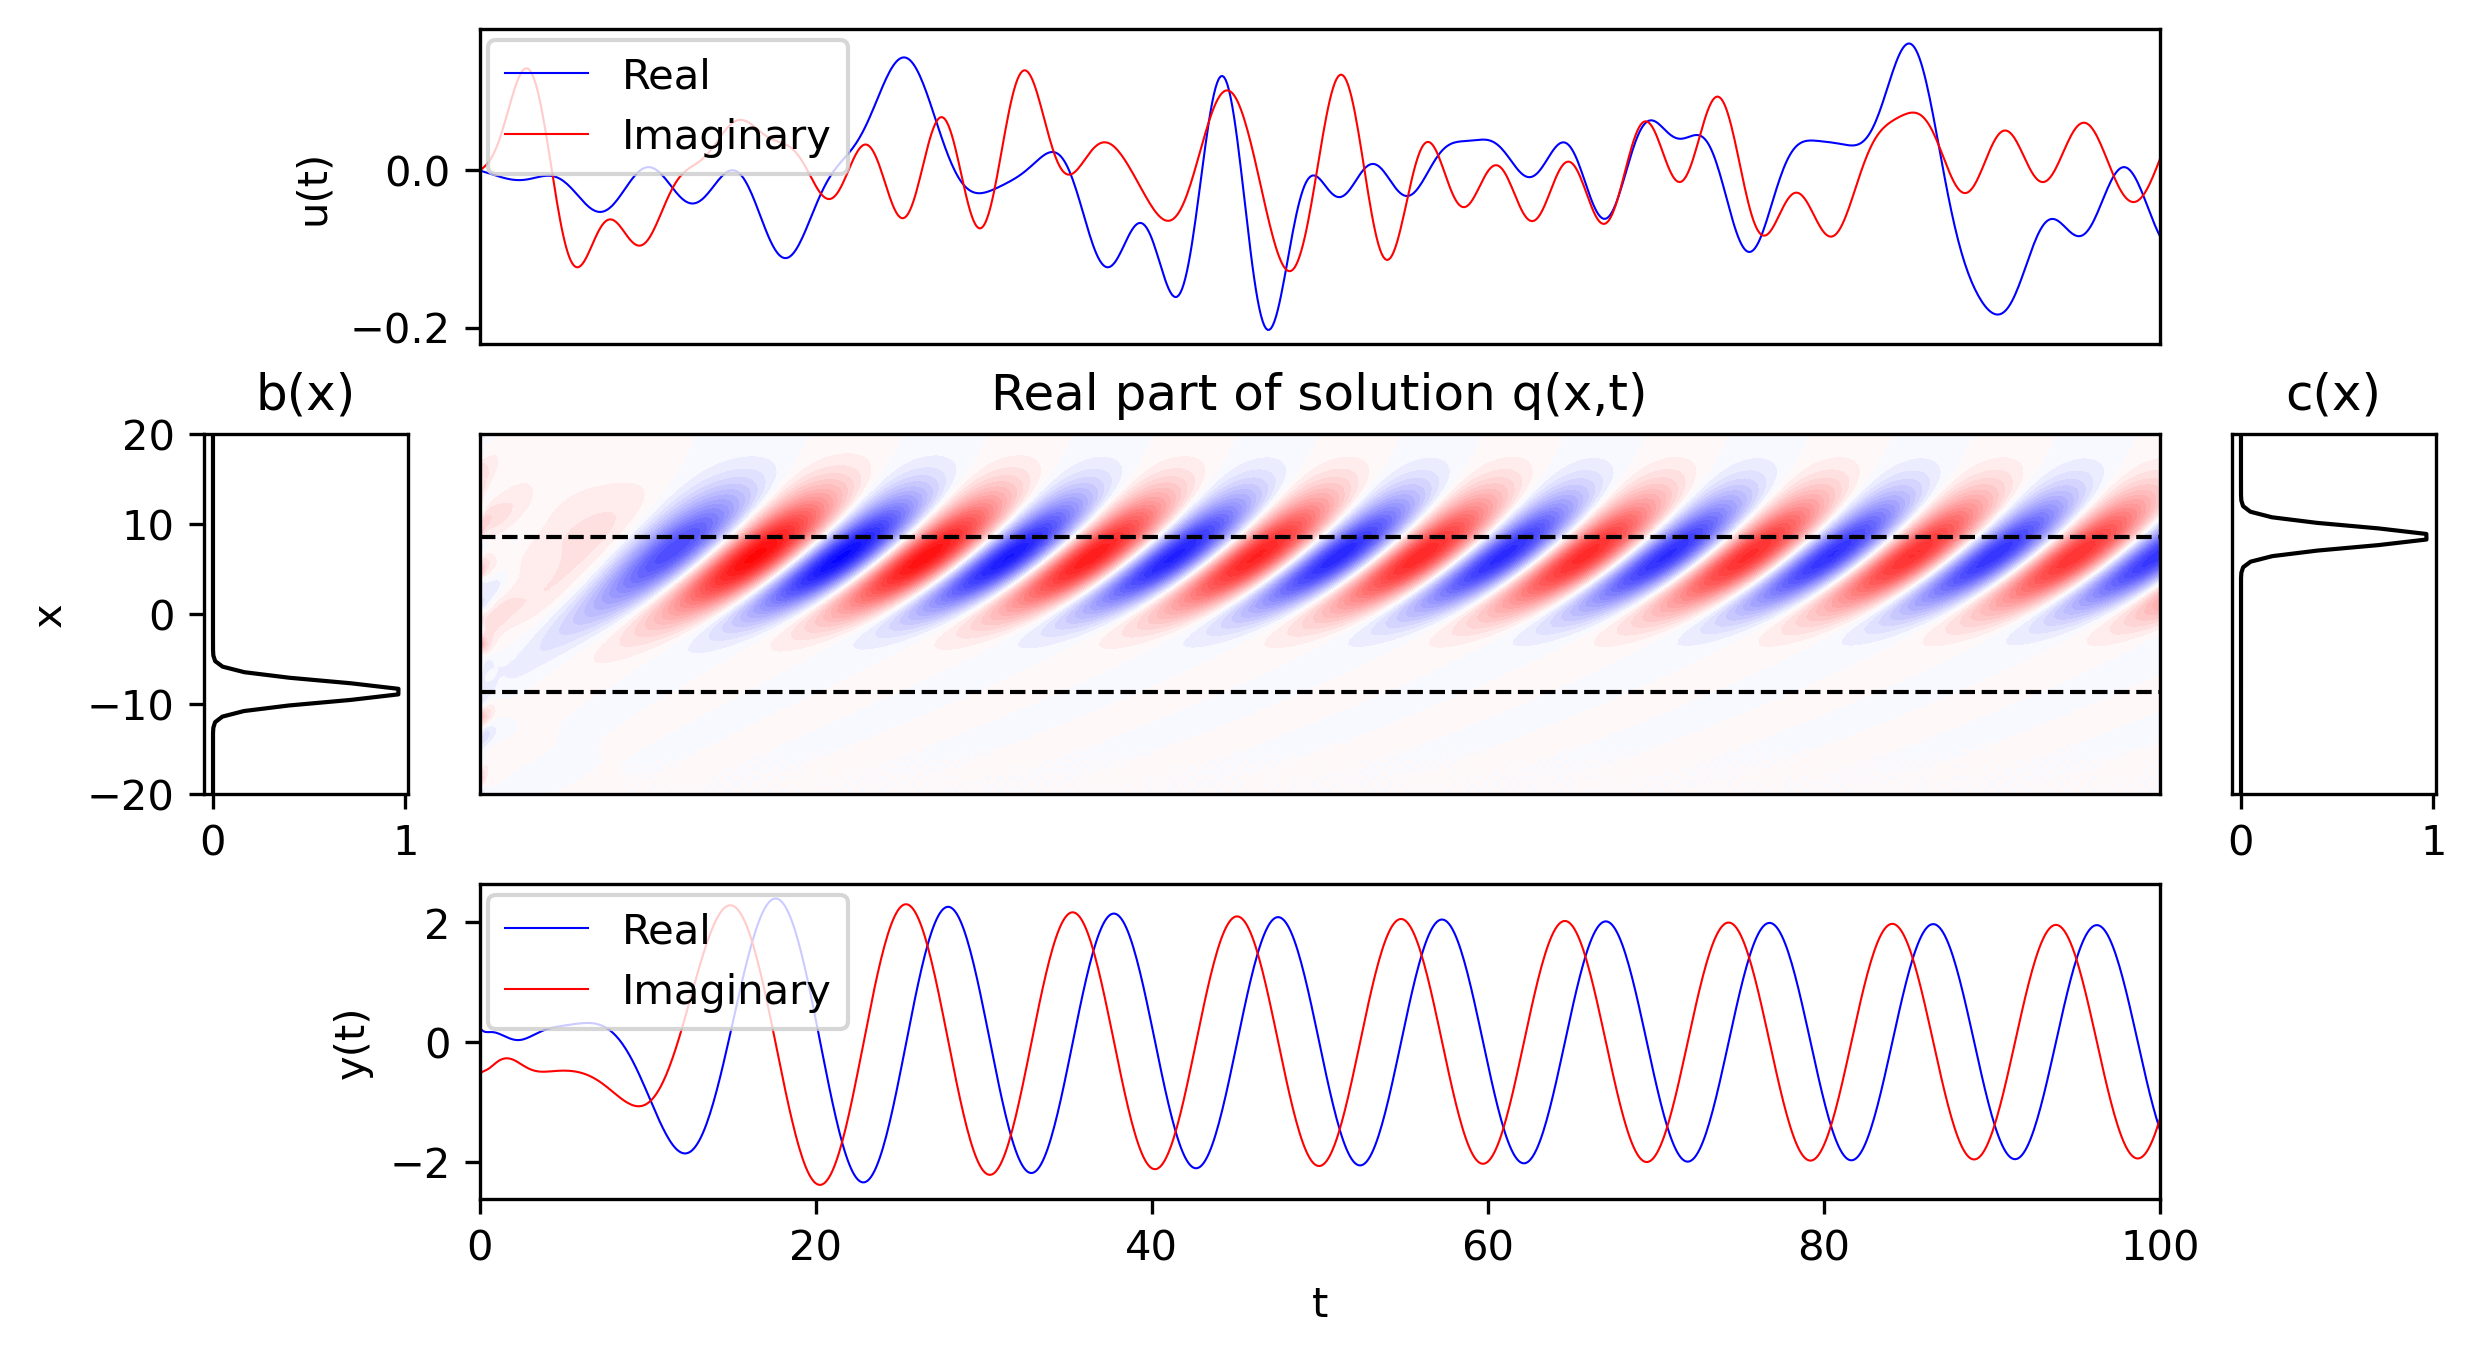

In [65]:
fig = plt.figure(figsize=(8,3), dpi=300)

p1 = 0.050
w1 = 0.085
p2 = 0.030
w2 = 0.700
p3 = 0.030
w3 = 0.085
p4 = 0.020

# print(p1+w1+p2+w2+p3+w3+p4) # should = 1

ax0 = plt.axes([p1+w1+p2, 1.05, w2, 0.35])
ax1 = plt.axes([p1, 0.55, w1, 0.4])
ax2 = plt.axes([p1+w1+p2, 0.55, w2, 0.4])
ax3 = plt.axes([p1+w1+p2+w2+p3, 0.55, w3, 0.4])
ax4 = plt.axes([p1+w1+p2, 0.10, w2, 0.35])

ax0.plot(t_data, u_data[0,:], 'b-', linewidth=0.5, label='Real')
ax0.plot(t_data, u_data[1,:], 'r-', linewidth=0.5, label='Imaginary')
ax0.legend(loc=(0.005,0.54))
ax0.set_xlim([0,t_data[-1]])
ax0.set_xticks([])
ax0.set_ylabel('u(t)')


# ax1.plot(q_IC[:nx]/np.sqrt(w_quad), xi_coll/chi, 'b-', linewidth=1.0)
# ax1.plot(q_IC[nx:]/np.sqrt(w_quad), xi_coll/chi, 'r-', linewidth=1.0)
# ax1.set_ylim([-20,20])
# # ax1.set_xticks(ticks=[-0.0005, 0.0005], labels=['-5e-4', '5e-4'])

ax1.plot(ker_inpt, xi_coll/chi, 'k-', linewidth=1.0)
ax1.set_ylim([-20,20])
ax1.set_xticks([0, 1])
# ax1.set_xticks(ticks=[-0.0005, 0.0005], labels=['-5e-4', '5e-4'])
ax1.set_ylabel('x')
ax1.set_title('b(x)')

tt, xx = np.meshgrid(t_data, xi_coll/chi)

surf = ax2.contourf(tt, xx, q_data[:nx,:]/np.reshape(np.sqrt(w_quad), (-1,1)), levels=50, cmap='bwr')
ax2.axhline(y=branch_1, color='k', linestyle='--', linewidth=1.0)
ax2.axhline(y=branch_2, color='k', linestyle='--', linewidth=1.0)
ax2.set_xticks([])
ax2.set_yticks([])
ax2.set_xlim([0,t_data[-1]])
ax2.set_ylim([-20,20])
ax2.set_title('Real part of solution q(x,t)')


ax3.plot(ker_obs, xi_coll/chi, 'k-', linewidth=1.0)
ax3.set_xticks([0, 1])
ax3.set_yticks([])
ax3.set_ylim([-20,20])
ax3.set_title('c(x)')

ax4.plot(t_data, y_data[0,:], 'b-', linewidth=0.5, label='Real')
ax4.plot(t_data, y_data[1,:], 'r-', linewidth=0.5, label='Imaginary')
ax4.legend(loc=(0.005,0.54))
ax4.set_xlim([0,t_data[-1]])
ax4.set_ylabel('y(t)')
ax4.set_xlabel('t')

# plt.savefig('figures/CGL_supercritical/training_trajectory.png', dpi=None, facecolor='w', edgecolor='w', \
#             transparent=False, bbox_inches=None, pad_inches=0.0)
# plt.savefig('figures/CGL_supercritical/training_trajectory.eps', dpi=None, facecolor='w', edgecolor='w', \
#             transparent=False, bbox_inches=None, pad_inches=0.0)
plt.show()

In [66]:
# set tolerance for solvers
atol = 1.0e-9
rtol = 1.0e-7
solver_method = 'RK45'

In [67]:
# System setup
n = A_FOM.shape[0]
m = B_FOM.shape[1]
p = C_FOM.shape[0]

Q = np.eye(p)
# A large R penalizes control effort strongly and may slow disturbance suppression
R = 1e2 * np.eye(m)

# Time grid: left Gauss–Radau nodes and weights
t0, tf = 0.0, 80
N = 200
t, w = gauss_radau_left(N, a=t0, b=tf)

def pack_u(U):
    return U.reshape(-1)

def unpack_u(u_vec):
    return u_vec.reshape(N, m)

def make_u_fun(u_vec):
    U = unpack_u(u_vec)
    return BarycentricInterpolator(t, U, axis=0)

# Forward simulation of the nonlinear FOM
# Dense output returns a continuous solution that can be evaluated at any time
def forward_trajectory(u_vec, x0):
    u_fun = make_u_fun(u_vec)

    def f(tq, x):
        return FOM(x, u_fun(tq))  # Nonlinear dynamics

    sol = solve_ivp(f, (t0, tf), x0, dense_output=True, method=solver_method, rtol=rtol, atol=atol)
    return sol.sol  # Return the continuous solution x(t), rather than a state array

# Cost functional
# X is the state array evaluated at quadrature nodes
def total_cost(u_vec, X):
    U = unpack_u(u_vec)
    Y = (C_FOM @ X.T).T
    stage_y = np.einsum('ij,ij->i', Y @ Q, Y)
    stage_u = np.einsum('ij,ij->i', U @ R, U)
    J = np.dot(w, stage_y + stage_u)
    return J

# Control gradient computed using the adjoint method
def gradient(u_vec, X, return_adj=False):
    u_fun = make_u_fun(u_vec)

    def adj_rhs(tq, p):
        xq = X(tq)
        return - d_FOM_adj(xq, u_fun(tq), p) - 2 * d_FOM_obs_adj(xq, Q @ FOM_obs(xq))

    pT = np.zeros(n)
    sol = solve_ivp(lambda tq, p: adj_rhs(tq, p), (tf, t0), pT, dense_output=True, method=solver_method, rtol=rtol, atol=atol)
    P = sol.sol(t).T  # Evaluate the continuous adjoint at quadrature nodes; shape (N, n)

    U = unpack_u(u_vec)
    BtP = np.array([B_FOM.T @ P[i] for i in range(len(P))])
    Gi = (BtP + 2.0 * (U @ R)) * w[:, None]

    if return_adj:
        return Gi.reshape(-1), P
    else:
        return Gi.reshape(-1)

# Objective and optimizer interfaces
def objective_with_grad(u_vec, x0):
    X_fun = forward_trajectory(u_vec, x0)
    X = X_fun(t).T  # Evaluate at quadrature nodes and transpose from (n, N) to (N, n)
    J = total_cost(u_vec, X)
    g = gradient(u_vec, X_fun)
    return J, g

def fun_only(u_vec, x0):
    return objective_with_grad(u_vec, x0)[0]  # Return the cost

def jac_only(u_vec, x0):
    return objective_with_grad(u_vec, x0)[1]  # Return the gradient with respect to control parameters

# Callback for recording and displaying optimization progress
iteration_data = []

def callback(u_vec, x0):
    J, g = objective_with_grad(u_vec, x0)
    grad_norm = np.linalg.norm(g)
    iteration_data.append((len(iteration_data), J, grad_norm))
    print(f"Iter {len(iteration_data):3d}: Cost = {J:.6f}, ||grad|| = {grad_norm:.3e}")

### Adjoint gradient verification

We check the adjoint gradient using a random unit control perturbation $v$. The directional derivative is compared with a forward finite-difference approximation:

$$
\nabla_{\mathbf{u}}J^\top v
\approx \frac{J(\mathbf{u}+\varepsilon v)-J(\mathbf{u})}{\varepsilon}.
$$

Both costs are evaluated by simulating the nonlinear FOM and applying quadrature at the time nodes. The function returns the relative discrepancy and both directional derivatives. A small error supports the correctness of the adjoint gradient.

In [68]:
def verify_adjoint_gradient(x0, N, m, t, forward_trajectory, gradient, total_cost, eps=1e-5):

    u_vec = np.random.randn(N * m)

    # Simulate the FOM and evaluate at quadrature nodes
    x_fun = forward_trajectory(u_vec, x0)
    X = x_fun(t).T

    # Compute the adjoint gradient using the continuous state trajectory
    g_analytic = gradient(u_vec, x_fun)

    # Random direction
    v = np.random.randn(*u_vec.shape)
    v /= np.linalg.norm(v)

    adj_deriv = np.dot(g_analytic, v)

    # Cost at base point
    J0 = total_cost(u_vec, X)

    # Perturb control in the direction of v
    u_pert = u_vec + eps * v

    # Forward for perturbed control
    x_fun_pert = forward_trajectory(u_pert, x0)
    X_pert = x_fun_pert(t).T

    J1 = total_cost(u_pert, X_pert)

    # Finite difference check
    fd_deriv = (J1 - J0) / eps

    # Relative error
    rel_err = np.abs(adj_deriv - fd_deriv) / np.abs(fd_deriv)

    return rel_err, adj_deriv, fd_deriv

In [69]:
rel_err, adj_deriv, fd_deriv= verify_adjoint_gradient(traj_ICs[0], N, m, t,forward_trajectory,gradient,total_cost, eps=1e-5)
print("\nAdjoint Gradient Verification")
print(f"Adjoint directional derivative : {adj_deriv:.6e}")
print(f"Finite diff directional deriv. : {fd_deriv:.6e}")
print(f"Ratio (adj/fd)                 : {adj_deriv/(fd_deriv + 1e-12):.6f}")
print(f"Relative error                 : {rel_err:.6e}")

# Use a smale relative error 
if rel_err < 1e-3:
        print("Gradient check PASSED")
else:
        print("Gradient check FAILED")


Adjoint Gradient Verification
Adjoint directional derivative : -2.445116e+01
Finite diff directional deriv. : -2.445505e+01
Ratio (adj/fd)                 : 0.999841
Relative error                 : 1.590655e-04
Gradient check PASSED


Iter   1: Cost = 169.858577, ||grad|| = 2.583e+03
Iter   2: Cost = 164.732606, ||grad|| = 3.199e+03
Iter   3: Cost = 157.801757, ||grad|| = 3.343e+03
Iter   4: Cost = 149.870856, ||grad|| = 2.823e+03
Iter   5: Cost = 140.624959, ||grad|| = 3.522e+03
Iter   6: Cost = 132.870089, ||grad|| = 3.828e+03
Iter   7: Cost = 129.319288, ||grad|| = 4.112e+03
Iter   8: Cost = 125.175888, ||grad|| = 4.278e+03
Iter   9: Cost = 121.878990, ||grad|| = 3.835e+03
Iter  10: Cost = 119.097601, ||grad|| = 4.112e+03
Iter  11: Cost = 114.999521, ||grad|| = 3.624e+03
Iter  12: Cost = 113.547549, ||grad|| = 3.402e+03
Iter  13: Cost = 111.486270, ||grad|| = 3.389e+03
Iter  14: Cost = 110.574948, ||grad|| = 3.197e+03
Iter  15: Cost = 109.349930, ||grad|| = 3.232e+03
Iter  16: Cost = 108.502600, ||grad|| = 3.471e+03
Iter  17: Cost = 107.709923, ||grad|| = 3.103e+03
Iter  18: Cost = 106.740436, ||grad|| = 3.164e+03
Iter  19: Cost = 105.902227, ||grad|| = 3.165e+03
Iter  20: Cost = 105.294978, ||grad|| = 2.883e+03


/opt/anaconda3/envs/control-env/lib/python3.11/site-packages/scipy/optimize/_minimize.py:779: OptimizeWarning: Desired error not necessarily achieved due to precision loss.
  res = _minimize_bfgs(fun, x0, args, jac, callback, **options)


         Current function value: 6.085132
         Iterations: 176
         Function evaluations: 220
         Gradient evaluations: 208

Optimization complete.
Final cost J* = 6.0851324496713834


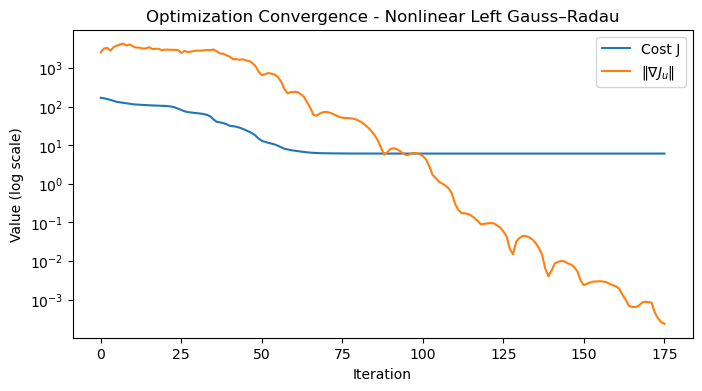

In [70]:
# Optimize the control for the first initial condition
x0 = traj_ICs[0]
U0 = 0 * np.ones((N, m))  # Zero initial control guess
u0 = pack_u(U0)

# Minimize the cost using BFGS with the adjoint gradient
res = minimize(fun_only, u0, args=(x0,), jac=jac_only, method="BFGS", tol=1e-6, options=dict(maxiter=800, gtol=1e-8, disp=True), callback=lambda u: callback(u, x0))

# Recover the optimized control, state trajectory, cost, and adjoint
u_star = unpack_u(res.x)
X_star_fun = forward_trajectory(res.x, x0)
X = X_star_fun(t).T  # Evaluate at quadrature nodes; shape (N, n)
J_star = total_cost(res.x, X)
Grad_star, P_star = gradient(res.x, X_star_fun, return_adj=True)

print("\nOptimization complete.")
print("Final cost J* =", J_star)

# Plot the cost and gradient norm recorded during optimization
if iteration_data:
    iters, costs, grads = zip(*iteration_data)
    plt.figure(figsize=(8, 4))
    plt.semilogy(iters, costs, label="Cost J")
    plt.semilogy(iters, grads, label=r"$\|\nabla J_u\|$")
    plt.xlabel("Iteration")
    plt.ylabel("Value (log scale)")
    plt.title("Optimization Convergence - Nonlinear Left Gauss–Radau")
    plt.legend()
    plt.minorticks_off()
    plt.grid(False)
    plt.show()

In [81]:
# # Generate offline training data 

# # Number of trajectories 
# n_samples_MC = len(traj_ICs)

# # Optimization for Multiple Random Samples
# dataset_CGLE_full_space = []   
# optimization_times = []

# # Start total timer
# total_start = time.perf_counter()

# for k in range(n_samples_MC):
#     # Clear the screen
#     clear_output(wait=True) 
    
#     if k>0 :
#         prev_cost = dataset_CGLE_full_space[k-1]['cost']
#         prev_x0 = dataset_CGLE_full_space[k-1]['x0']
#         prev_time = dataset_CGLE_full_space[k-1]['optimization_time']
#         print(f"Previous Sample {k}: J* = {prev_cost:.6f}, optimization time = {prev_time:.2f} seconds")

#     else:
#         print("Starting first sample...")

#     print(f"Sample {k+1}/{n_samples_MC} running...")
    
#     # Reset iteration tracker
#     iteration_data = []

#     # Use the kth pre-generated initial condition
#     x0 = traj_ICs[k]
    
#     # Initial control guess
#     U0 = 0 * np.ones((N, m))   # Initial guess (zeros)
#     u0 = pack_u(U0)

#     # Start timer for this optimization
#     opt_start = time.perf_counter()

#     # Run optimization for this initial condition 
#     res = minimize(
#         fun_only, u0,
#         args=(x0,),
#         jac=jac_only,
#         method='BFGS',
#         tol=1e-6,
#         options=dict(maxiter=800, gtol=1e-8, disp=False),
#         callback=lambda u: callback(u, x0)
#     )

#     # End timer for this optimization
#     opt_time = time.perf_counter() - opt_start
#     optimization_times.append(opt_time)

#     # Compute final trajectories and adjoints
#     u_star = unpack_u(res.x)
#     X_star_fun = forward_trajectory(res.x,x0)
#     X_star = X_star_fun(t).T                  # Evaluate at nodes - X_fun returns n by N and transpose to get N by n 
#     J_star = total_cost(res.x, X_star)
#     Grad_star, P_star = gradient(res.x, X_star_fun, return_adj=True)

#     Y_star = (C_FOM @ X_star.T).T

#     # Stage cost (vectorized)
#     L = np.einsum('ij,ij->i', Y_star @ Q, Y_star) + \
#     np.einsum('ij,ij->i', u_star @ R, u_star)

#     # Value function (vectorized)
#     V = np.cumsum((w * L)[::-1])[::-1]

#     # Store structured dataset entry 
#     dataset_CGLE_full_space.append({
#         'x0': x0,
#         'state_history': X_star,
#         'control_history': u_star,
#         'gradient_history': P_star,
#         'cost': J_star,
#         'Value_function': V,
#         'optimization_time': opt_time,
#     })
    
#     print(f"\nSample {k+1}/{n_samples_MC} complete, J* = {J_star:.6f}")

# # Total time
# total_time = time.perf_counter() - total_start
        
# print(f"Optimization from {n_samples_MC} initial samples done and completed")
# print(f"Total optimization time = {total_time:.2f} seconds")
# print(f"Average time per optimization = {np.mean(optimization_times):.2f} seconds")